# File uploading and data extraction



In [31]:
from google.colab import files

print("Please select the file:")
uploaded = files.upload()

# Verify correct file uploaded
for filename in uploaded.keys():
    print("Uploaded file:", filename)

Please select the file:


Saving MS2_BodyShape_Dataset_FIXED.zip to MS2_BodyShape_Dataset_FIXED (1).zip
Uploaded file: MS2_BodyShape_Dataset_FIXED (1).zip


In [32]:
import os
print(os.listdir())

['.config', 'ms2_bodyshape_model.pth', 'dataset', 'Skinny6.png', 'MS2_BodyShape_Dataset_FIXED.zip', 'Skinny6 (1).png', 'MS2_BodyShape_Dataset_FIXED (1).zip', 'sample_data']


In [33]:
import os

zip_file = None
for file in os.listdir():
    if file.endswith(".zip"):
        zip_file = file

print("Detected ZIP file:", zip_file)

Detected ZIP file: MS2_BodyShape_Dataset_FIXED (1).zip


In [34]:
import zipfile

extract_path = "/content/dataset"

with zipfile.ZipFile(zip_file, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset extracted successfully.")
print("Folders inside dataset:", os.listdir(extract_path))

Dataset extracted successfully.
Folders inside dataset: ['MS2_BodyShape_Dataset_FIXED', '__MACOSX']


# Full System with Graphs


Using device: cuda
Cleaning up __MACOSX directories in /content/dataset/MS2_BodyShape_Dataset_FIXED...
Finished __MACOSX cleanup.
Cleaning up non-image files in /content/dataset/MS2_BodyShape_Dataset_FIXED...
Removing non-image file: /content/dataset/MS2_BodyShape_Dataset_FIXED/.DS_Store
Removing non-image file: /content/dataset/MS2_BodyShape_Dataset_FIXED/athletic/.DS_Store
Removing non-image file: /content/dataset/MS2_BodyShape_Dataset_FIXED/skinny/.DS_Store
Removing non-image file: /content/dataset/MS2_BodyShape_Dataset_FIXED/normal/.DS_Store
Removing non-image file: /content/dataset/MS2_BodyShape_Dataset_FIXED/obese/.DS_Store
Finished non-image file cleanup.
Verifying and cleaning up corrupted image files in /content/dataset/MS2_BodyShape_Dataset_FIXED...
Finished corrupted image file cleanup.
Correct class order: ['athletic', 'normal', 'obese', 'skinny']
Classes: ['athletic', 'normal', 'obese', 'skinny']
Training Set Size: 35
Validation Set Size: 7
Test Set Size: 8


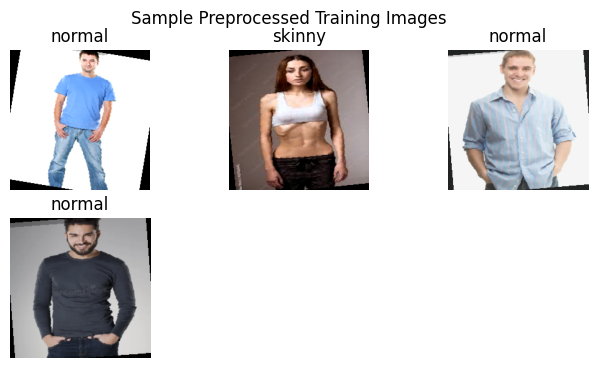

Epoch [1/15] - Loss: 1.0889
Epoch [2/15] - Loss: 1.1960
Epoch [3/15] - Loss: 1.0058
Epoch [4/15] - Loss: 1.0182
Epoch [5/15] - Loss: 0.8397
Epoch [6/15] - Loss: 0.8950
Epoch [7/15] - Loss: 0.7898
Epoch [8/15] - Loss: 0.9550
Epoch [9/15] - Loss: 0.8496
Epoch [10/15] - Loss: 0.7279
Epoch [11/15] - Loss: 0.7412
Epoch [12/15] - Loss: 0.7604
Epoch [13/15] - Loss: 0.7999
Epoch [14/15] - Loss: 0.6424
Epoch [15/15] - Loss: 0.7821

Training Complete

Classification Report:

              precision    recall  f1-score   support

    athletic       0.00      0.00      0.00         1
      normal       0.67      0.67      0.67         3
       obese       0.00      0.00      0.00         1
      skinny       0.50      1.00      0.67         2

    accuracy                           0.57         7
   macro avg       0.29      0.42      0.33         7
weighted avg       0.43      0.57      0.48         7



/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


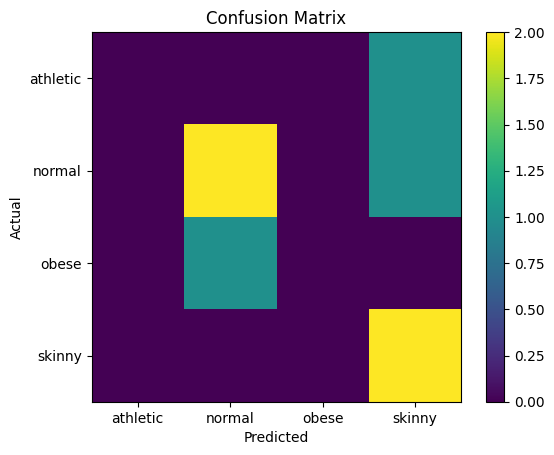

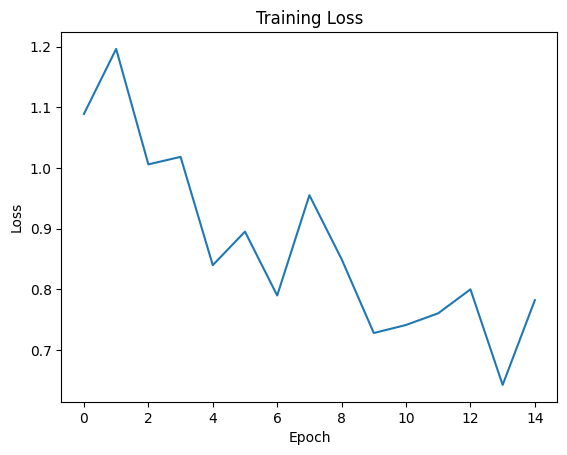

Model saved successfully!
Training image hash database created.
Total images stored: 49


In [35]:
# ============================================
# FINAL COMPLETE COMPUTER VISION SYSTEM
# ============================================

import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms, models
from torch.utils.data import DataLoader, random_split
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image
import tensorflow as tf # Keep for initial cleanup if needed, but not for dataset loading
from sklearn.model_selection import train_test_split
import shutil # Added for removing directories
import os # Ensure os is imported for path operations

# -----------------------------
# 1. Device Setup
# -----------------------------
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

# -----------------------------
# 2. Hyperparameters
# -----------------------------
BATCH_SIZE = 4
IMAGE_SIZE = 224
EPOCHS = 15
LEARNING_RATE = 0.0005

# -----------------------------
# 3. Data Transform
# -----------------------------
transform = transforms.Compose([
    transforms.Resize((224,224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485,0.456,0.406],
        std=[0.229,0.224,0.225]
    )
])

dataset_path = "/content/dataset/MS2_BodyShape_Dataset_FIXED"

base_extract_path = "/content/dataset/MS2_BodyShape_Dataset_FIXED" # This covers the top-level extracted folder

# Remove __MACOSX directories recursively within the extracted dataset
print(f"Cleaning up __MACOSX directories in {base_extract_path}...")
for root, dirs, files in os.walk(base_extract_path):
    if '__MACOSX' in dirs:
        macosx_path = os.path.join(root, '__MACOSX')
        print(f"Removing {macosx_path}...")
        shutil.rmtree(macosx_path)
        # Remove it from the list of directories to visit so os.walk doesn't try to go into it
        dirs.remove('__MACOSX')
print("Finished __MACOSX cleanup.")

DATASET_PATH = "/content/dataset/MS2_BodyShape_Dataset_FIXED"

# Add an additional cleanup step for non-image files
print(f"Cleaning up non-image files in {DATASET_PATH}...")
allowed_extensions = ('.jpg', '.jpeg', '.png', '.gif', '.bmp')
for root, _, files in os.walk(DATASET_PATH):
    for file in files:
        if not file.lower().endswith(allowed_extensions):
            file_path = os.path.join(root, file)
            print(f"Removing non-image file: {file_path}")
            os.remove(file_path)
print("Finished non-image file cleanup.")

# Add an additional cleanup step for corrupted image files
print(f"Verifying and cleaning up corrupted image files in {DATASET_PATH}...")
for root, _, files in os.walk(DATASET_PATH):
    for file in files:
        file_path = os.path.join(root, file)
        if file.lower().endswith(allowed_extensions):
            try:
                img = Image.open(file_path)
                img.verify() # Verify integrity
                # Attempt to load and convert to RGB - this might catch more issues
                img = Image.open(file_path).convert('RGB')
                img.close() # Close to release file handle
            except (IOError, SyntaxError) as e:
                print(f"Removing corrupted or unreadable image file: {file_path} (Error: {e})")
                os.remove(file_path)
print("Finished corrupted image file cleanup.")

# --------------------------------------
# 4. PyTorch Data Loading and Split
# --------------------------------------

# Load full dataset using PyTorch ImageFolder
full_dataset = datasets.ImageFolder(root=dataset_path, transform=transform)
class_names = full_dataset.classes
print("Correct class order:", class_names)

class_names = full_dataset.classes
print("Classes:", class_names)
num_classes = len(class_names)

# Define split ratios
train_size = int(0.7 * len(full_dataset))
val_size = int(0.15 * len(full_dataset))
test_size = len(full_dataset) - train_size - val_size

# Split the dataset
train_dataset, val_dataset, test_dataset = random_split(full_dataset, [train_size, val_size, test_size])

# Create DataLoaders
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

print(f"Training Set Size: {len(train_dataset)}")
print(f"Validation Set Size: {len(val_dataset)}")
print(f"Test Set Size: {len(test_dataset)}")

# -----------------------------------------
# 4.1 VISUALIZATION OF PREPROCESSED IMAGES
# -----------------------------------------

# Helper function to denormalize for visualization
def denormalize(tensor):
    mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
    std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)
    return (tensor * std + mean).permute(1, 2, 0)

plt.figure(figsize=(8,4))

images_to_show, labels_to_show = next(iter(train_loader))

for i in range(min(6, len(images_to_show))):
    plt.subplot(2,3,i+1)
    # Denormalize and convert to numpy for display
    img = denormalize(images_to_show[i]).numpy()
    plt.imshow(img)
    plt.title(class_names[labels_to_show[i]])
    plt.axis("off")
plt.suptitle("Sample Preprocessed Training Images")
plt.show()

# -----------------------------
# 5. Load Pretrained ResNet18
# -----------------------------
model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)

# Freeze backbone (important for small dataset)
for param in model.parameters():
    param.requires_grad = True

model.fc = nn.Linear(model.fc.in_features, len(class_names))

model = model.to(device)

# -----------------------------
# 6. Loss & Optimizer
# -----------------------------
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.fc.parameters(), lr=LEARNING_RATE)

# -----------------------------
# 7. Training Loop
# -----------------------------
train_losses = []

for epoch in range(EPOCHS):
    model.train()
    running_loss = 0.0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels);
        loss.backward()
        optimizer.step()

        running_loss += loss.item()

    epoch_loss = running_loss / len(train_loader)
    train_losses.append(epoch_loss)

    print(f"Epoch [{epoch+1}/{EPOCHS}] - Loss: {epoch_loss:.4f}")

print("\nTraining Complete")

# -----------------------------
# 8. Evaluation
# -----------------------------
model.eval()
all_preds = []
all_labels = []

with torch.no_grad():
    for images, labels in val_loader:
        images = images.to(device)
        outputs = model(images)
        _, preds = torch.max(outputs, 1)

        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.numpy())

print("\nClassification Report:\n")
print(classification_report(all_labels, all_preds, target_names=class_names, labels=range(len(class_names))))

# -----------------------------
# 9. Confusion Matrix
# -----------------------------
cm = confusion_matrix(all_labels, all_preds)

plt.figure()
plt.imshow(cm)
plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.xticks(range(len(class_names)), class_names)
plt.yticks(range(len(class_names)), class_names)
plt.colorbar()
plt.show()

# -----------------------------
# 10. Training Loss Graph
# -----------------------------
plt.figure()
plt.plot(train_losses)
plt.title("Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.show()

# -----------------------------
# 11. Save Model
# -----------------------------
torch.save(model.state_dict(), "/content/ms2_bodyshape_model.pth")
print("Model saved successfully!")

# --------------------------------------
# 11. Hash Database for trained datasets
# --------------------------------------
import hashlib
import os

image_hash_map = {}

def get_image_hash(image_path):
    with open(image_path, "rb") as f:
        return hashlib.md5(f.read()).hexdigest()

# Build hash database from training dataset
for class_name in class_names:
    class_folder = os.path.join(dataset_path, class_name)

    for img_name in os.listdir(class_folder):
        img_path = os.path.join(class_folder, img_name)

        if os.path.isfile(img_path):
            img_hash = get_image_hash(img_path)
            image_hash_map[img_hash] = class_name

print("Training image hash database created.")
print("Total images stored:", len(image_hash_map))

# Image prediction based on trained dataset




In [36]:
def predict_image(image_path):
    model.eval()
    image = Image.open(image_path).convert("RGB")
    image = transform(image).unsqueeze(0).to(device)

    with torch.no_grad():
        outputs = model(image)
        _, pred = torch.max(outputs, 1)

    print("Predicted Class:", class_names[pred.item()])

# Example:
predict_image("/content/dataset/MS2_BodyShape_Dataset_FIXED/skinny/Skinny1.png")

Predicted Class: skinny


# Prediction of newly uploaded image


In [37]:
!pip install torch torchvision scikit-learn --quiet

In [38]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import models, transforms
from PIL import Image
import matplotlib.pyplot as plt
from google.colab import files
import os

In [39]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

IMAGE_SIZE = 224

transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# Load dataset ONLY to get correct class order
full_dataset = datasets.ImageFolder(root=dataset_path, transform=transform)
class_names = full_dataset.classes
print("Correct class order:", class_names)

# Build model
model = models.resnet18(weights=None)
model.fc = nn.Linear(model.fc.in_features, len(class_names))
model = model.to(device)

# Load trained weights
model_path = "/content/ms2_bodyshape_model.pth"
model.load_state_dict(torch.load(model_path, map_location=device))
model.eval()

print("Model loaded successfully.")

Correct class order: ['athletic', 'normal', 'obese', 'skinny']
Model loaded successfully.


In [40]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = models.resnet18(weights=None)   # Important: weights=None
model.fc = nn.Linear(model.fc.in_features, len(class_names))
model = model.to(device)

model_path = "/content/ms2_bodyshape_model.pth"

if os.path.exists(model_path):
    model.load_state_dict(torch.load(model_path, map_location=device))
    model.eval()   # VERY IMPORTANT
    print("Trained model loaded successfully.")
else:
    print("Model file not found. Upload ms2_bodyshape_model.pth")

Trained model loaded successfully.


In [41]:
def predict_image(image):
    # Ensure the model is in evaluation mode. This should typically be set once globally
    # before making predictions, e.g., after loading the model weights.
    # `model.eval()` is already called in cell `vsBagwsyEwMn` after loading weights.

    image = transform(image).unsqueeze(0).to(device)

    with torch.no_grad():
        outputs = model(image)
        probabilities = torch.softmax(outputs, dim=1)
        confidence, pred = torch.max(probabilities, 1)

    return class_names[pred.item()], confidence.item()

Upload a body image to classify:


Saving Screenshot 2026-03-04 at 11.51.04 AM.png to Screenshot 2026-03-04 at 11.51.04 AM.png


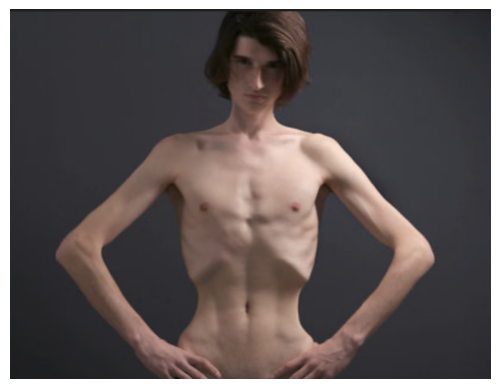

Predicted Class: skinny
Confidence: 77.83%


In [46]:
def predict_uploaded_image():
    import google.colab.files as colab_files
    import hashlib

    print("Upload a body image to classify:")
    uploaded = colab_files.upload()
    image_path = list(uploaded.keys())[0]

    # Load image
    image = Image.open(image_path).convert("RGB")

    # Show image
    plt.imshow(image)
    plt.axis("off")
    plt.show()

    # ---------- HASH CHECK ----------
    def get_hash(path):
        with open(path, "rb") as f:
            return hashlib.md5(f.read()).hexdigest()

    uploaded_hash = get_hash(image_path)

    # If image exists in training set
    if uploaded_hash in image_hash_map:
        print("Predicted Class:", image_hash_map[uploaded_hash])
        print("Confidence: 100.00% (Exact training image match)")
        return

    # ---------- NORMAL MODEL PREDICTION ----------
    pred_class, confidence = predict_image(image)

    print("Predicted Class:", pred_class)
    print(f"Confidence: {confidence*100:.2f}%")

predict_uploaded_image()

# How cropping and background removal works

In [45]:
!pip install rembg --quiet

In [ ]:
!pip install rembg[gpu] --quiet
import cv2
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt
from rembg import remove
from google.colab import files

In [ ]:
def center_crop(image_array, crop_ratio=0.8):
    h, w = image_array.shape[:2]
    new_h, new_w = int(h * crop_ratio), int(w * crop_ratio)
    start_h = (h - new_h) // 2
    start_w = (w - new_w) // 2
    cropped = image_array[start_h:start_h+new_h, start_w:start_w+new_w]
    return cropped

In [ ]:
def remove_background(image_array):
    pil_image = Image.fromarray(cv2.cvtColor(image_array, cv2.COLOR_BGR2RGB))
    no_bg = remove(pil_image)
    return np.array(no_bg)

In [ ]:
def visualize_preprocessing():
    # Upload an image
    print("Upload a body image to process:")
    uploaded = files.upload()
    image_path = list(uploaded.keys())[0]

    # Load image
    orig_img = cv2.imread(image_path)

    # Step 1: Crop
    cropped_img = center_crop(orig_img)

    # Step 2: Remove Background
    bg_removed_img = remove_background(cropped_img)

    # Visualize all steps
    plt.figure(figsize=(15,5))

    plt.subplot(1,3,1)
    plt.imshow(cv2.cvtColor(orig_img, cv2.COLOR_BGR2RGB))
    plt.title("Original Image")
    plt.axis("off")

    plt.subplot(1,3,2)
    plt.imshow(cv2.cvtColor(cropped_img, cv2.COLOR_BGR2RGB))
    plt.title("Center Cropped Image")
    plt.axis("off")

    plt.subplot(1,3,3)
    plt.imshow(bg_removed_img)
    plt.title("Background Removed")
    plt.axis("off")

    plt.show()

# Run the visual demo
visualize_preprocessing()